# Task 1: Analyse Example Data
**Group 1 Metric**: Bennett, Alpert, and Goldstein’s S


In [1]:
import json
import glob
import os
import pandas as pd

# Load example data files (works from annotation_experiment/ or the repo root)
files = sorted(glob.glob("example_data/*.jsonl")) or sorted(
    glob.glob("annotation_experiment/example_data/*.jsonl"))

# Read each json line from the batch files
data = []
for f in files:
    with open(f, "r", encoding="utf-8") as fp:
        for line in fp:
            line = line.strip()
            if line:
                data.append(json.loads(line))

# Convert into a pandas DataFrame
df = pd.DataFrame(data)
print(f"Total samples loaded: {len(df)}")


Total samples loaded: 81


## 1. Check for Missing Data


In [2]:
# Check if any samples have missing annotators or missing labels
missing_samples = 0

for _, row in df.iterrows():
    anns = row.get("labels_annotation", [])
    # Verify that both Anna and Max annotated this sample
    if len(anns) != 2:
        missing_samples += 1

print(f"Samples with missing annotations: {missing_samples} (out of {len(df)})")
print(f"Batches in dataset: {list(df['batch_number'].unique())}")


Samples with missing annotations: 0 (out of 81)
Batches in dataset: [np.int64(14), np.int64(43)]


## 2. 2x2 Matrix: "offensive" vs "not offensive"


In [3]:
# Extract binary label for a specific annotator
def get_user_label(labels_list, user):
    for entry in labels_list:
        if entry.get("user") == user:
            lbls = entry.get("labels", [])
            # Return offensive if tagged offensive, otherwise not offensive
            return "offensive" if "offensive" in lbls else "not offensive"
    return "missing"

# Create separate columns for Anna and Max
df["anna"] = df["labels_annotation"].apply(lambda lst: get_user_label(lst, "anna"))
df["max"] = df["labels_annotation"].apply(lambda lst: get_user_label(lst, "max"))

# Compute 2x2 matrix for All Data (81 samples)
print("=== 2x2 Matrix (All Data, N = 81) ===")
matrix_all = pd.crosstab(df["anna"], df["max"], rownames=["Anna"], colnames=["Max"], margins=True)
print(matrix_all)

# Compute 2x2 matrix for Batch 14 (30 samples)
print("\n=== 2x2 Matrix (Batch 14, N = 30) ===")
print(pd.crosstab(df[df["batch_number"] == 14]["anna"], df[df["batch_number"] == 14]["max"], rownames=["Anna"], colnames=["Max"], margins=True))

# Compute 2x2 matrix for Batch 43 (51 samples)
print("\n=== 2x2 Matrix (Batch 43, N = 51) ===")
print(pd.crosstab(df[df["batch_number"] == 43]["anna"], df[df["batch_number"] == 43]["max"], rownames=["Anna"], colnames=["Max"], margins=True))


=== 2x2 Matrix (All Data, N = 81) ===
Max            not offensive  offensive  All
Anna                                        
not offensive             62          5   67
offensive                  2         12   14
All                       64         17   81

=== 2x2 Matrix (Batch 14, N = 30) ===
Max            not offensive  offensive  All
Anna                                        
not offensive             21          4   25
offensive                  1          4    5
All                       22          8   30

=== 2x2 Matrix (Batch 43, N = 51) ===
Max            not offensive  offensive  All
Anna                                        
not offensive             41          1   42
offensive                  1          8    9
All                       42          9   51


## 3. Percentage Agreement & Bennett, Alpert, and Goldstein’s S

- **Percentage Agreement ($P_o$)**:
  $$P_o = \frac{\text{Number of Agreed Samples}}{N}$$

- **Bennett, Alpert, and Goldstein’s S**:
  $$S = 1 - \frac{k(1 - P_o)}{k - 1}$$
  For $k = 2$ categories (offensive / not offensive):
  $$S = 1 - \frac{2(1 - P_o)}{2 - 1} = 2P_o - 1$$


In [4]:
def compute_metrics(subset, name="All Data"):
    # Total number of samples in this subset
    n = len(subset)

    #Count rows where Anna's label equals Max's label
    agreements = (subset["anna"] == subset["max"]).sum()

    #Calculate observed percentage agreement - P0
    po = agreements / n
    
    # Calculate Bennett's S with k=2: S = 2*Po - 1
    k = 2
    s = 1.0 - (k * (1.0 - po)) / (k - 1.0)
    
    return {
        "Subset": name,
        "N": n,
        "Agreements": agreements,
        "Disagreements": n - agreements,
        "Percentage Agreement (Po)": f"{po:.4f} ({po:.2%})",
        "Bennett's S": f"{s:.4f} ({s:.2%})",
        "po_val": po,
        "s_val": s
    }

# Compute metrics for each batch and for all data
results = [
    compute_metrics(df[df["batch_number"] == 14], "Batch 14"),
    compute_metrics(df[df["batch_number"] == 43], "Batch 43"),
    compute_metrics(df, "All Data")
]

# Display summary table
summary_df = pd.DataFrame(results)
display_cols = ["Subset", "N", "Agreements", "Disagreements", "Percentage Agreement (Po)", "Bennett's S"]
summary_df[display_cols]


,Subset,N,Agreements,Disagreements,Percentage Agreement (Po),Bennett's S
0,Batch 14,30,25,5,0.8333 (83.33%),0.6667 (66.67%)
1,Batch 43,51,49,2,0.9608 (96.08%),0.9216 (92.16%)
2,All Data,81,74,7,0.9136 (91.36%),0.8272 (82.72%)


## 4. Visualizing Percentage Agreement vs. Bennett’s S


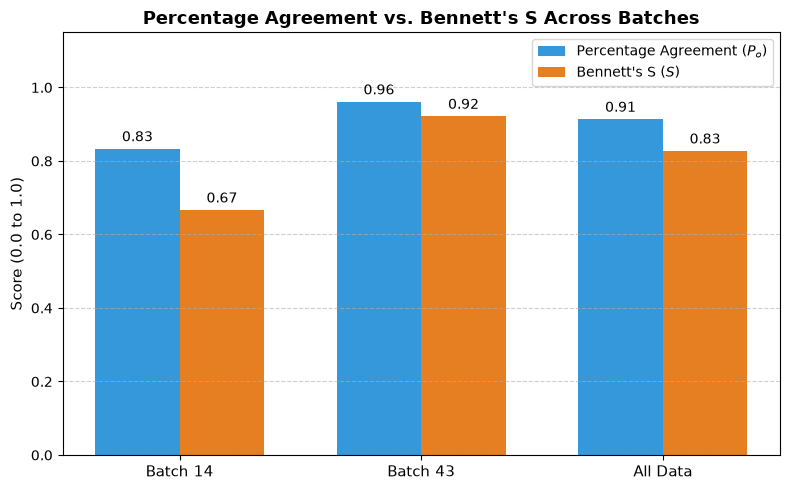

In [5]:
import matplotlib.pyplot as plt

# Set x positions and bar width
x = range(len(summary_df))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars for Percentage Agreement (blue) and Bennett's S (orange)
bars1 = ax.bar([i - width/2 for i in x], summary_df["po_val"], width=width, label="Percentage Agreement ($P_o$)", color="#3498db")
bars2 = ax.bar([i + width/2 for i in x], summary_df["s_val"], width=width, label="Bennett's S ($S$)", color="#e67e22")

# Set labels and title
ax.set_xticks(list(x))
ax.set_xticklabels(summary_df["Subset"], fontsize=11)
ax.set_ylabel("Score (0.0 to 1.0)", fontsize=11)
ax.set_title("Percentage Agreement vs. Bennett's S Across Batches", fontsize=13, fontweight="bold")
ax.set_ylim(0, 1.15)
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.6)

# Display exact scores on top of each bar
ax.bar_label(bars1, fmt="%.2f", padding=3, fontsize=10)
ax.bar_label(bars2, fmt="%.2f", padding=3, fontsize=10)

plt.tight_layout()
plt.show()
